# 03 — Évaluation rigoureuse sur le test officiel

Le **test officiel (624 images)** n'a servi à rien jusqu'ici : ni à l'entraînement, ni à l'early
stopping, ni au choix du seuil. C'est la seule estimation honnête de la performance.

**Les métriques, en clair** (pneumonie = classe positive) :
- **Sensibilité** (rappel) = pneumonies détectées / toutes les pneumonies. Un faux négatif est une
  pneumonie ratée : c'est l'erreur la plus grave en contexte médical.
- **Spécificité** = radios normales reconnues / toutes les normales. Un faux positif est une fausse alerte.
- **Précision** (VPP) = parmi les alertes, proportion de vraies pneumonies.
- **AUC-ROC** : probabilité qu'une pneumonie tirée au hasard reçoive un score plus élevé qu'une radio
  normale tirée au hasard. Ne dépend d'aucun seuil.
- **Intervalles de confiance à 95 %** par bootstrap (2 000 rééchantillonnages du test).

**Choix du seuil.** Le modèle donne une probabilité ; il faut un seuil pour décider. On compare :
1. le seuil par défaut **0,5** ;
2. un seuil **« haute sensibilité »**, choisi **sur la validation** comme le plus grand seuil qui détecte
   au moins **98 %** des pneumonies de validation (cible fixée à l'avance), puis appliqué tel quel au test.

In [1]:
import sys
from pathlib import Path

# Le notebook est dans notebooks/ : on remonte à la racine du dépôt pour importer src/
RACINE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RACINE))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
pd.set_option("display.precision", 3)
%matplotlib inline
%config InlineBackend.figure_formats = ["jpeg"]
%config InlineBackend.print_figure_kwargs = {"dpi": 90, "bbox_inches": "tight"}
import json
from src.data import DOSSIER_FIGURES, DOSSIER_RESULTATS
from src.evaluate import (calculer_predictions, evaluer_tout, tableau_markdown, figure_roc,
                          figure_matrices, figure_distribution, metriques_au_seuil, MODELES)
pred_val, pred_test = calculer_predictions()
pred_val.to_csv(DOSSIER_RESULTATS / "predictions_val.csv", index=False)
pred_test.to_csv(DOSSIER_RESULTATS / "predictions_test.csv", index=False)
resultats = evaluer_tout(pred_val, pred_test)
with open(DOSSIER_RESULTATS / "metriques.json", "w", encoding="utf-8") as f:
    json.dump(resultats, f, indent=2, ensure_ascii=False)
tableau = tableau_markdown(resultats)
(DOSSIER_RESULTATS / "tableau_resultats.md").write_text(tableau, encoding="utf-8")
display(Markdown(tableau))

| Modèle | Seuil | AUC-ROC | Sensibilité | Spécificité | Précision | F1 | Accuracy | FN | FP |
|---|---|---|---|---|---|---|---|---|---|
| Baseline (petit CNN) | 0,50 | 0.926 [0.902–0.947] | 0.910 [0.880–0.937] | 0.795 [0.741–0.846] | 0.881 [0.848–0.912] | 0.895 [0.872–0.917] | 0.867 [0.840–0.893] | 35 | 48 |
| Baseline (petit CNN) | 0.092 (sens. val ≥ 98%) | 0.926 [0.902–0.947] | 0.987 [0.976–0.997] | 0.500 [0.437–0.563] | 0.767 [0.730–0.804] | 0.863 [0.839–0.887] | 0.804 [0.774–0.835] | 5 | 117 |
| DenseNet-121 | 0,50 | 0.976 [0.961–0.988] | 0.992 [0.982–1.000] | 0.812 [0.760–0.860] | 0.898 [0.870–0.926] | 0.943 [0.926–0.958] | 0.925 [0.904–0.944] | 3 | 44 |
| DenseNet-121 | 0.206 (sens. val ≥ 98%) | 0.976 [0.961–0.988] | 0.992 [0.982–1.000] | 0.744 [0.683–0.797] | 0.866 [0.832–0.896] | 0.925 [0.906–0.942] | 0.899 [0.875–0.921] | 3 | 60 |

In [2]:
# Validation vs test : le modèle se comporte-t-il de la même façon ?
for nom in MODELES:
    for cle in ["0.5", "haute_sensibilite"]:
        v, t = resultats[nom][cle]["val"], resultats[nom][cle]["test"]
        print(f"{nom:12s} seuil {t['seuil']:.3f} | VAL sens {v['sensibilite']:.3f} spec {v['specificite']:.3f} "
              f"AUC {v['auc']:.4f} | TEST sens {t['sensibilite']:.3f} spec {t['specificite']:.3f} AUC {t['auc']:.4f}")

baseline     seuil 0.500 | VAL sens 0.901 spec 0.979 AUC 0.9911 | TEST sens 0.910 spec 0.795 AUC 0.9258
baseline     seuil 0.092 | VAL sens 0.980 spec 0.922 AUC 0.9911 | TEST sens 0.987 spec 0.500 AUC 0.9258
densenet121  seuil 0.500 | VAL sens 0.968 spec 0.995 AUC 0.9989 | TEST sens 0.992 spec 0.812 AUC 0.9757
densenet121  seuil 0.206 | VAL sens 0.980 spec 0.984 AUC 0.9989 | TEST sens 0.992 spec 0.744 AUC 0.9757


## 1. Courbe ROC

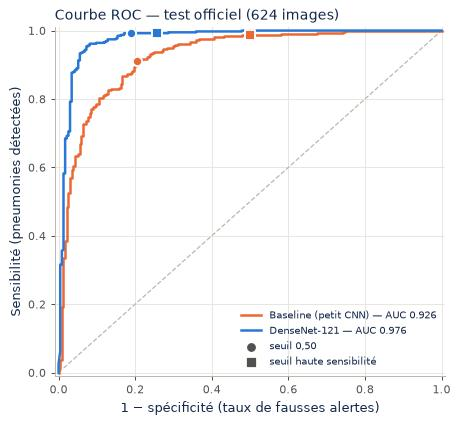

In [3]:
figure_roc(pred_test, resultats, DOSSIER_FIGURES / "roc_test.png");

## 2. Matrices de confusion du modèle principal

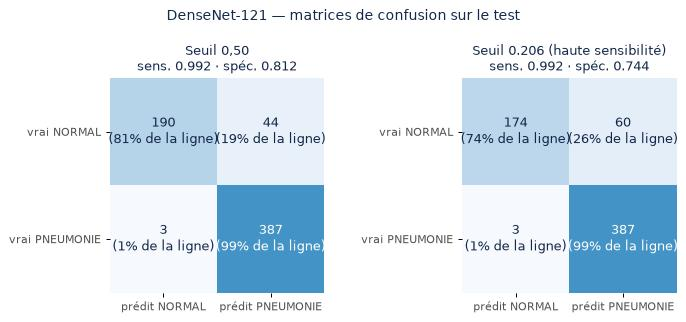

In [4]:
figure_matrices(resultats, chemin=DOSSIER_FIGURES / "matrices_confusion.png");

## 3. Distribution des probabilités : validation vs test

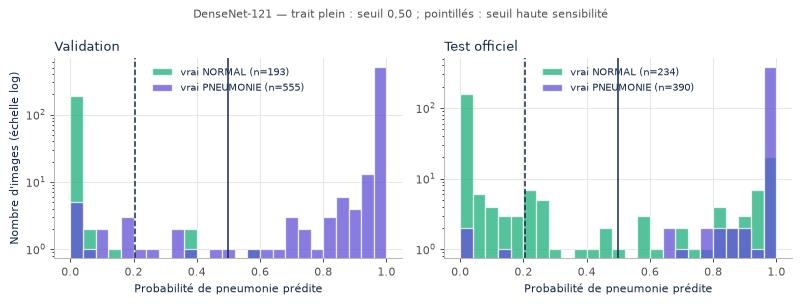

In [5]:
figure_distribution(pred_val, pred_test, resultats, chemin=DOSSIER_FIGURES / "distribution_probas.png");

## 4. Les erreurs dépendent-elles du sous-type de pneumonie ?

In [6]:
s = resultats["densenet121"]["0.5"]["test"]["seuil"]
t = pred_test.assign(pred=(pred_test.proba_densenet121 >= s).astype(int))
t["correct"] = t.pred == t.label
display(t.groupby("sous_type").agg(n=("label", "size"), taux_correct=("correct", "mean")).round(3))

,n,taux_correct
sous_type,,
bacteria,242,0.992
normal,234,0.812
virus,148,0.993


### Ce que disent les résultats
- **DenseNet-121 au seuil 0,5** : AUC **0,976** [0,961–0,988], sensibilité **0,992** (3 pneumonies ratées sur 390), spécificité **0,812** (44 fausses alertes sur 234 normales).
- **Baseline au seuil 0,5** : AUC 0,926 [0,902–0,947], sensibilité 0,910 (35 ratées), spécificité 0,795 (48 fausses alertes). Le DenseNet pré-entraîné fait nettement mieux : les intervalles d'AUC ne se chevauchent pas, et il rate 3 pneumonies au lieu de 35.
- **Écart validation → test** : pour le DenseNet, la spécificité passe de 0,995 en validation à 0,812 en test, et l'AUC de 0,999 à 0,976. Les erreurs du test sont presque toutes des **fausses alertes sur des radios normales** (81,2 % des normales bien classées, contre 99,2 % des pneumonies bactériennes et 99,3 % des virales). Le test ne ressemble donc pas tout à fait au train et à la validation : la proportion diffère (62,5 % contre 74 % de pneumonies), et la distribution des probabilités le montre aussi.
- **Choix du seuil** : le seuil « haute sensibilité » (0,206, choisi sur la validation) n'apporte rien sur ce test pour le DenseNet. La sensibilité y était déjà à 0,992 (les mêmes 3 ratées), et la spécificité baisse à 0,744 (16 fausses alertes de plus). Pour la baseline, l'arbitrage est visible : sensibilité 0,910 → 0,987 (35 → 5 ratées), spécificité 0,795 → 0,500 (48 → 117 fausses alertes).
- **À retenir** : un seuil se choisit selon l'usage (dépistage ou confirmation) et sur des données **représentatives de la population cible**. Ici, la validation ne l'est pas complètement. Avec 234 radios normales seulement, la spécificité reste incertaine d'environ ±5 points.